# 06 — Frozen-policy final test evaluation

This notebook performs the held-out final test evaluation after the validation-selected policy has been committed and verified byte-for-byte against `HEAD`. It does not search hyperparameters, calibration methods, feature sets, or thresholds. The completed workflow includes one identical rerun after a display-only string syntax error halted the first attempt after scoring; no model choice or value was changed.

Outputs cover overall performance with bootstrap uncertainty, validation-to-test generalization, performance by side / market activity / trading day, calibration curves, and row-level predictions for auditability.


## Evaluation guardrail

Before reading any test target, the notebook verifies all of the following:

1. the Git worktree is clean;
2. the frozen policy file exactly matches the version committed at `HEAD`;
3. the policy status is `validation_selected_test_not_evaluated`;
4. all three horizons have a fixed model, calibration method, and decision threshold.

The policy file is not updated after evaluation. A separate final-test summary records the policy hash, source commit, and evaluation results.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import subprocess
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import calibration_curve

RANDOM_SEED = 42
HORIZONS = (5, 30, 60)
BOOTSTRAP_RESAMPLES = 1000

project_root_override = os.environ.get("LIMIT_ORDER_PROJECT_ROOT")
PROJECT_ROOT = Path(project_root_override) if project_root_override else Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = Path(os.environ.get("LIMIT_ORDER_ARTIFACT_DIR", PROJECT_ROOT / "results"))
FIGURE_DIR = Path(os.environ.get("LIMIT_ORDER_FIGURE_DIR", PROJECT_ROOT / "reports" / "figures"))
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from history_features import add_order_side_features, build_history_features
from modeling import FEATURE_SETS, add_oriented_static_features
from evaluation import (
    apply_sigmoid_calibrator,
    bootstrap_metric_intervals,
    build_estimator,
    fit_sigmoid_calibrator,
    safe_probability_metrics,
)

warnings.filterwarnings("ignore", category=FutureWarning)

POLICY_PATH = PROJECT_ROOT / "results" / "selected_model_policy.json"
policy_bytes = POLICY_PATH.read_bytes()
policy_sha256 = hashlib.sha256(policy_bytes).hexdigest()
source_commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, text=True
).strip()
workspace_status = subprocess.check_output(
    ["git", "status", "--porcelain"], cwd=PROJECT_ROOT, text=True
).strip()
tracked_policy_bytes = subprocess.check_output(
    ["git", "show", "HEAD:results/selected_model_policy.json"], cwd=PROJECT_ROOT
)

assert workspace_status == "", "Worktree must be clean before opening test targets."
assert policy_bytes == tracked_policy_bytes, "Policy file differs from the committed version."

policy = json.loads(policy_bytes)
assert policy["status"] == "validation_selected_test_not_evaluated"
assert set(policy["horizons"]) == {str(horizon) for horizon in HORIZONS}
assert all(policy["horizons"][str(h)]["calibration"] == "sigmoid" for h in HORIZONS)

print("Frozen policy verified before test access")
print("Source commit:", source_commit)
print("Policy SHA-256:", policy_sha256)
print("Worktree clean:", workspace_status == "")
print("Test targets accessed so far: 0")


Frozen policy verified before test access
Source commit: 2dd1dbb42449aa4a78c3cbb7743b9d9047b728c2
Policy SHA-256: 92a6631d142c8cd493898b9c1934ebed4ac553b9dc41e189b4323b2d60a3f78d
Worktree clean: True
Test targets accessed so far: 0


## Frozen fitting protocol

For each horizon, the final estimator uses the feature set, model family, hyperparameters, calibration method, and threshold already selected in notebook 05.

- Four expanding-window folds on the 14 training days recreate the out-of-fold probabilities used to fit the sigmoid calibrator.
- The base estimator is then fitted on all eligible training rows.
- Validation rows are not used for refitting or any new decision.
- The calibrated test probabilities are classified with the unchanged validation-selected threshold.


In [2]:
excel_files = sorted(RAW_DIR.glob("*.xlsx"))
assert len(excel_files) == 1
EXCEL_PATH = excel_files[0]

# The held-out test labels are first read here, after all policy checks above pass.
orders = pd.read_excel(EXCEL_PATH, sheet_name="Orders")
orders["data_split_normalized"] = orders["data_split"].astype(str).str.lower()
orders["trading_day_parsed"] = pd.to_datetime(orders["trading_day"])

assert len(orders) == 10_000
assert orders["order_id"].is_unique
assert orders["data_split_normalized"].value_counts().to_dict() == {
    "train": 7_000,
    "validation": 1_500,
    "test": 1_500,
}

split_day_bounds = orders.groupby("data_split_normalized")["trading_day_parsed"].agg(["min", "max"])
assert split_day_bounds.loc["train", "max"] < split_day_bounds.loc["validation", "min"]
assert split_day_bounds.loc["validation", "max"] < split_day_bounds.loc["test", "min"]

orders = add_oriented_static_features(orders)

# Historical JSON is loaded only if the frozen policy actually selected feature set D.
selected_feature_sets = {
    policy["horizons"][str(horizon)]["feature_set"] for horizon in HORIZONS
}
if "D_full_history" in selected_feature_sets:
    json_files = sorted(list(RAW_DIR.glob("*.json")) + list(RAW_DIR.glob("*.json.gz")))
    assert len(json_files) == 1
    history_features = build_history_features(json_files[0])
    check_columns = [column for column in history_features if column.startswith("check_")]
    assert len(history_features) == 10_000
    assert history_features[check_columns].all().all()
    orders = orders.merge(history_features, on="order_id", how="left", validate="one_to_one")
    orders = add_order_side_features(orders)

for feature_set_name in selected_feature_sets:
    assert orders[FEATURE_SETS[feature_set_name]].notna().all().all()

training_rows = orders.loc[orders["data_split_normalized"].eq("train")].copy()
validation_rows = orders.loc[orders["data_split_normalized"].eq("validation")].copy()
test_rows = orders.loc[orders["data_split_normalized"].eq("test")].copy()

print("Test set opened after guardrail checks")
print("Rows — train / validation / test:", len(training_rows), len(validation_rows), len(test_rows))
display(split_day_bounds)


Test set opened after guardrail checks
Rows — train / validation / test: 7000 1500 1500


,min,max
data_split_normalized,,
test,2022-09-29,2022-10-03
train,2022-09-06,2022-09-23
validation,2022-09-26,2022-09-28


In [3]:
training_days = sorted(training_rows["trading_day_parsed"].unique())
assert len(training_days) == 14

fold_day_specs = [
    (training_days[:6], training_days[6:8]),
    (training_days[:8], training_days[8:10]),
    (training_days[:10], training_days[10:12]),
    (training_days[:12], training_days[12:14]),
]

fold_audit_rows = []
for horizon in HORIZONS:
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"
    for fold_number, (fit_days, score_days) in enumerate(fold_day_specs, start=1):
        fit_mask = training_rows["trading_day_parsed"].isin(fit_days) & training_rows[eligibility].eq(1)
        score_mask = training_rows["trading_day_parsed"].isin(score_days) & training_rows[eligibility].eq(1)
        fold_audit_rows.append({
            "horizon_seconds": horizon,
            "fold": fold_number,
            "fit_start": str(pd.Timestamp(min(fit_days)).date()),
            "fit_end": str(pd.Timestamp(max(fit_days)).date()),
            "score_start": str(pd.Timestamp(min(score_days)).date()),
            "score_end": str(pd.Timestamp(max(score_days)).date()),
            "fit_rows": int(fit_mask.sum()),
            "score_rows": int(score_mask.sum()),
            "fit_fill_rate": float(training_rows.loc[fit_mask, target].mean()),
            "score_fill_rate": float(training_rows.loc[score_mask, target].mean()),
        })

fold_audit = pd.DataFrame(fold_audit_rows)
display(fold_audit.round(4))


,horizon_seconds,fold,fit_start,fit_end,score_start,score_end,fit_rows,score_rows,fit_fill_rate,score_fill_rate
0,5,1,2022-09-06,2022-09-13,2022-09-14,2022-09-15,2925,979,0.1056,0.0858
1,5,2,2022-09-06,2022-09-15,2022-09-16,2022-09-19,3904,961,0.1007,0.1082
2,5,3,2022-09-06,2022-09-19,2022-09-20,2022-09-21,4865,975,0.1022,0.1097
3,5,4,2022-09-06,2022-09-21,2022-09-22,2022-09-23,5840,967,0.1034,0.1107
4,30,1,2022-09-06,2022-09-13,2022-09-14,2022-09-15,2648,890,0.4173,0.3933
5,30,2,2022-09-06,2022-09-15,2022-09-16,2022-09-19,3538,878,0.4112,0.4328
6,30,3,2022-09-06,2022-09-19,2022-09-20,2022-09-21,4416,887,0.4155,0.4307
7,30,4,2022-09-06,2022-09-21,2022-09-22,2022-09-23,5303,870,0.4181,0.4184
8,60,1,2022-09-06,2022-09-13,2022-09-14,2022-09-15,2473,831,0.6276,0.5921
9,60,2,2022-09-06,2022-09-15,2022-09-16,2022-09-19,3304,822,0.6186,0.6691


## One-time test scoring

No candidate comparison occurs below. There is exactly one frozen policy per horizon.


In [4]:
prediction_frames = []
overall_rows = []
fit_summary_rows = []

for horizon in HORIZONS:
    horizon_policy = policy["horizons"][str(horizon)]
    feature_set_name = horizon_policy["feature_set"]
    model_name = horizon_policy["model"]
    parameters = horizon_policy["parameters"]
    threshold = float(horizon_policy["selected_threshold"])
    features = FEATURE_SETS[feature_set_name]
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"

    oof_probabilities = []
    oof_targets = []
    for fit_days, score_days in fold_day_specs:
        fit_mask = training_rows["trading_day_parsed"].isin(fit_days) & training_rows[eligibility].eq(1)
        score_mask = training_rows["trading_day_parsed"].isin(score_days) & training_rows[eligibility].eq(1)
        fold_estimator = build_estimator(
            feature_set_name,
            model_name,
            parameters,
            random_seed=RANDOM_SEED,
        )
        fold_estimator.fit(
            training_rows.loc[fit_mask, features],
            training_rows.loc[fit_mask, target].astype(int),
        )
        oof_probabilities.append(
            fold_estimator.predict_proba(training_rows.loc[score_mask, features])[:, 1]
        )
        oof_targets.append(training_rows.loc[score_mask, target].astype(int).to_numpy())

    oof_probability = np.concatenate(oof_probabilities)
    oof_target = np.concatenate(oof_targets)
    calibrator = fit_sigmoid_calibrator(oof_probability, oof_target)

    train_mask = training_rows[eligibility].eq(1)
    test_mask = test_rows[eligibility].eq(1)
    final_estimator = build_estimator(
        feature_set_name,
        model_name,
        parameters,
        random_seed=RANDOM_SEED,
    )
    final_estimator.fit(
        training_rows.loc[train_mask, features],
        training_rows.loc[train_mask, target].astype(int),
    )

    raw_probability = final_estimator.predict_proba(test_rows.loc[test_mask, features])[:, 1]
    probability = apply_sigmoid_calibrator(calibrator, raw_probability)
    y_test = test_rows.loc[test_mask, target].astype(int).to_numpy()
    predictions = (probability >= threshold).astype(int)

    metrics = safe_probability_metrics(y_test, probability, threshold)
    intervals = bootstrap_metric_intervals(
        y_test,
        probability,
        threshold,
        random_seed=RANDOM_SEED + horizon,
        resamples=BOOTSTRAP_RESAMPLES,
    )
    overall_row = {
        "horizon_seconds": horizon,
        "candidate": horizon_policy["candidate"],
        "feature_set": feature_set_name,
        "model": model_name,
        "calibration": horizon_policy["calibration"],
        "selected_threshold": threshold,
        **metrics,
    }
    for metric, bounds in intervals.items():
        overall_row[f"{metric}_ci_low"] = bounds["ci_low"]
        overall_row[f"{metric}_ci_high"] = bounds["ci_high"]
    overall_rows.append(overall_row)

    fit_summary_rows.append({
        "horizon_seconds": horizon,
        "training_eligible_rows": int(train_mask.sum()),
        "calibration_oof_rows": int(len(oof_target)),
        "test_eligible_rows": int(test_mask.sum()),
        "feature_count": len(features),
    })

    prediction_frame = test_rows.loc[
        test_mask,
        ["order_id", "trading_day", "side", "market_activity_group"],
    ].copy()
    prediction_frame["horizon_seconds"] = horizon
    prediction_frame["target_fill"] = y_test
    prediction_frame["raw_probability"] = raw_probability
    prediction_frame["calibrated_probability"] = probability
    prediction_frame["selected_threshold"] = threshold
    prediction_frame["predicted_fill"] = predictions
    prediction_frames.append(prediction_frame)

overall_metrics = pd.DataFrame(overall_rows).sort_values("horizon_seconds")
fit_summary = pd.DataFrame(fit_summary_rows)
test_predictions = pd.concat(prediction_frames, ignore_index=True)

display_columns = [
    "horizon_seconds", "candidate", "eligible_rows", "true_fill_rate",
    "predicted_fill_rate", "roc_auc", "pr_auc", "brier_score", "ece_10",
    "precision", "recall", "f1",
]
display(overall_metrics[display_columns].round(4))
display(fit_summary)


,horizon_seconds,candidate,eligible_rows,true_fill_rate,predicted_fill_rate,roc_auc,pr_auc,brier_score,ece_10,precision,recall,f1
0,5,B_logistic,1460,0.1178,0.0644,0.6163,0.1696,0.1023,0.0138,0.2234,0.1221,0.1579
1,30,C_random_forest,1311,0.4447,0.6423,0.6499,0.5995,0.2298,0.0350,0.5166,0.7461,0.6105
2,60,C_random_forest,1234,0.6434,0.9635,0.6896,0.8052,0.2051,0.0275,0.6577,0.9849,0.7887


,horizon_seconds,training_eligible_rows,calibration_oof_rows,test_eligible_rows,feature_count
0,5,6807,3882,1460,39
1,30,6173,3525,1311,49
2,60,5777,3304,1234,49


## Validation-to-test generalization

The comparison is descriptive only. Test results do not trigger any model, calibration, or threshold change.


In [5]:
comparison_rows = []
comparison_metrics = (
    "roc_auc", "pr_auc", "brier_score", "ece_10",
    "accuracy", "precision", "recall", "f1",
)
for row in overall_metrics.to_dict("records"):
    horizon = int(row["horizon_seconds"])
    validation_metrics = policy["horizons"][str(horizon)]["validation_metrics"]
    comparison_row = {"horizon_seconds": horizon}
    for metric in comparison_metrics:
        comparison_row[f"validation_{metric}"] = float(validation_metrics[metric])
        comparison_row[f"test_{metric}"] = float(row[metric])
        comparison_row[f"delta_{metric}"] = float(row[metric] - validation_metrics[metric])
    comparison_rows.append(comparison_row)

validation_test_comparison = pd.DataFrame(comparison_rows)
display(
    validation_test_comparison[
        [
            "horizon_seconds",
            "validation_pr_auc", "test_pr_auc", "delta_pr_auc",
            "validation_brier_score", "test_brier_score", "delta_brier_score",
            "validation_f1", "test_f1", "delta_f1",
        ]
    ].round(4)
)


,horizon_seconds,validation_pr_auc,test_pr_auc,delta_pr_auc,validation_brier_score,test_brier_score,delta_brier_score,validation_f1,test_f1,delta_f1
0,5,0.2466,0.1696,-0.0771,0.0872,0.1023,0.0151,0.3216,0.1579,-0.1637
1,30,0.6043,0.5995,-0.0048,0.2138,0.2298,0.0160,0.5987,0.6105,0.0118
2,60,0.7976,0.8052,0.0077,0.2108,0.2051,-0.0058,0.7671,0.7887,0.0216


## Stability slices

Each slice uses the same frozen probability model and threshold. Small groups should be read with their row count and class balance; no subgroup-specific threshold is fitted.


In [6]:
slice_rows = []
for horizon in HORIZONS:
    horizon_predictions = test_predictions.loc[
        test_predictions["horizon_seconds"].eq(horizon)
    ]
    threshold = float(policy["horizons"][str(horizon)]["selected_threshold"])
    for dimension in ("side", "market_activity_group", "trading_day"):
        for group_value, group in horizon_predictions.groupby(dimension, sort=True):
            metrics = safe_probability_metrics(
                group["target_fill"].to_numpy(),
                group["calibrated_probability"].to_numpy(),
                threshold,
            )
            slice_rows.append({
                "horizon_seconds": horizon,
                "dimension": dimension,
                "group": str(group_value),
                **metrics,
            })

slice_metrics = pd.DataFrame(slice_rows)

for dimension in ("side", "market_activity_group", "trading_day"):
    print()
    print(dimension)
    display(
        slice_metrics.loc[
            slice_metrics["dimension"].eq(dimension),
            [
                "horizon_seconds", "group", "eligible_rows", "true_fill_rate",
                "predicted_fill_rate", "roc_auc", "pr_auc", "brier_score",
                "precision", "recall", "f1",
            ],
        ].round(4)
    )



side


,horizon_seconds,group,eligible_rows,true_fill_rate,predicted_fill_rate,roc_auc,pr_auc,brier_score,precision,recall,f1
0,5,buy,739,0.1164,0.0731,0.6423,0.1658,0.1010,0.1852,0.1163,0.1429
1,5,sell,721,0.1193,0.0555,0.5891,0.1804,0.1036,0.2750,0.1279,0.1746
8,30,buy,662,0.4577,0.6511,0.6562,0.6155,0.2301,0.5313,0.7558,0.6240
9,30,sell,649,0.4314,0.6333,0.6423,0.5847,0.2294,0.5012,0.7357,0.5962
16,60,buy,618,0.6683,0.9612,0.6970,0.8226,0.1978,0.6835,0.9831,0.8064
17,60,sell,616,0.6185,0.9659,0.6813,0.7871,0.2124,0.6319,0.9869,0.7705



market_activity_group


,horizon_seconds,group,eligible_rows,true_fill_rate,predicted_fill_rate,roc_auc,pr_auc,brier_score,precision,recall,f1
2,5,high,68,0.1176,0.1029,0.5750,0.2202,0.1023,0.2857,0.2500,0.2667
3,5,low,561,0.1176,0.0660,0.5992,0.1657,0.1030,0.2162,0.1212,0.1553
4,5,medium,831,0.1179,0.0602,0.6334,0.1810,0.1018,0.2200,0.1122,0.1486
10,30,high,65,0.4769,0.8615,0.7087,0.6672,0.2243,0.5179,0.9355,0.6667
11,30,low,511,0.4051,0.4462,0.6187,0.5220,0.2340,0.4781,0.5266,0.5011
12,30,medium,735,0.4694,0.7592,0.6622,0.6425,0.2273,0.5323,0.8609,0.6578
18,60,high,63,0.6825,1.0000,0.7465,0.8543,0.1899,0.6825,1.0000,0.8113
19,60,low,485,0.5773,0.9588,0.6749,0.7480,0.2199,0.5935,0.9857,0.7409
20,60,medium,686,0.6866,0.9636,0.6729,0.8261,0.1960,0.7005,0.9830,0.8180



trading_day


,horizon_seconds,group,eligible_rows,true_fill_rate,predicted_fill_rate,roc_auc,pr_auc,brier_score,precision,recall,f1
5,5,2022-09-29,488,0.1230,0.0697,0.5793,0.1593,0.1081,0.1765,0.1000,0.1277
6,5,2022-09-30,489,0.1247,0.0695,0.5833,0.1635,0.1085,0.2353,0.1311,0.1684
7,5,2022-10-03,483,0.1056,0.0538,0.6900,0.2366,0.0902,0.2692,0.1373,0.1818
13,30,2022-09-29,445,0.4517,0.6539,0.6588,0.5935,0.2321,0.5292,0.7662,0.6260
14,30,2022-09-30,424,0.4222,0.6439,0.6353,0.5821,0.2278,0.4872,0.7430,0.5885
15,30,2022-10-03,442,0.4593,0.6290,0.6554,0.6326,0.2292,0.5324,0.7291,0.6154
21,60,2022-09-29,428,0.6682,0.9626,0.7098,0.8216,0.1929,0.6893,0.9930,0.8138
22,60,2022-09-30,396,0.6010,0.9697,0.7033,0.7905,0.2139,0.6120,0.9874,0.7556
23,60,2022-10-03,410,0.6585,0.9585,0.6579,0.8049,0.2093,0.6692,0.9741,0.7934


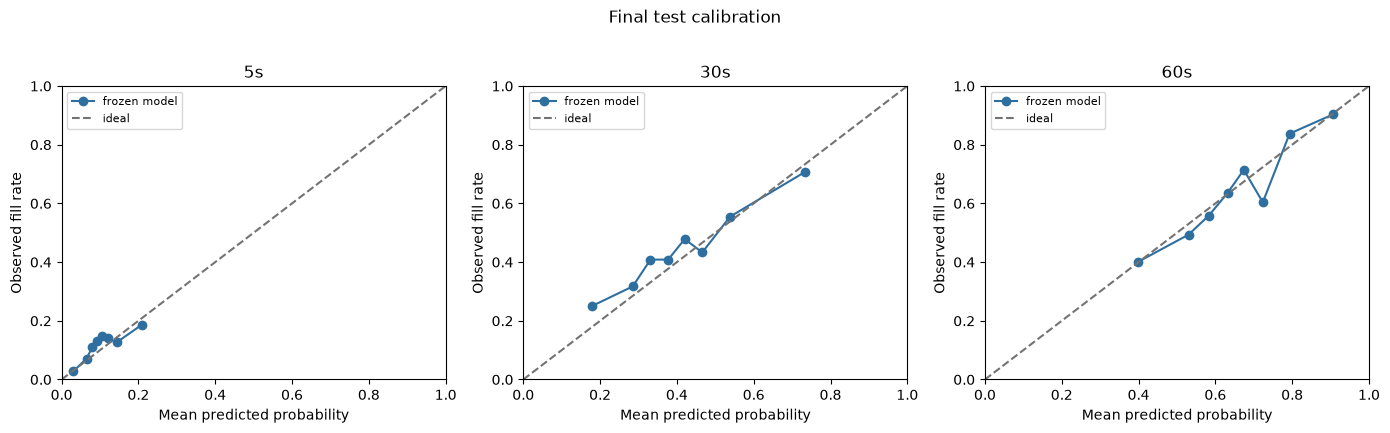

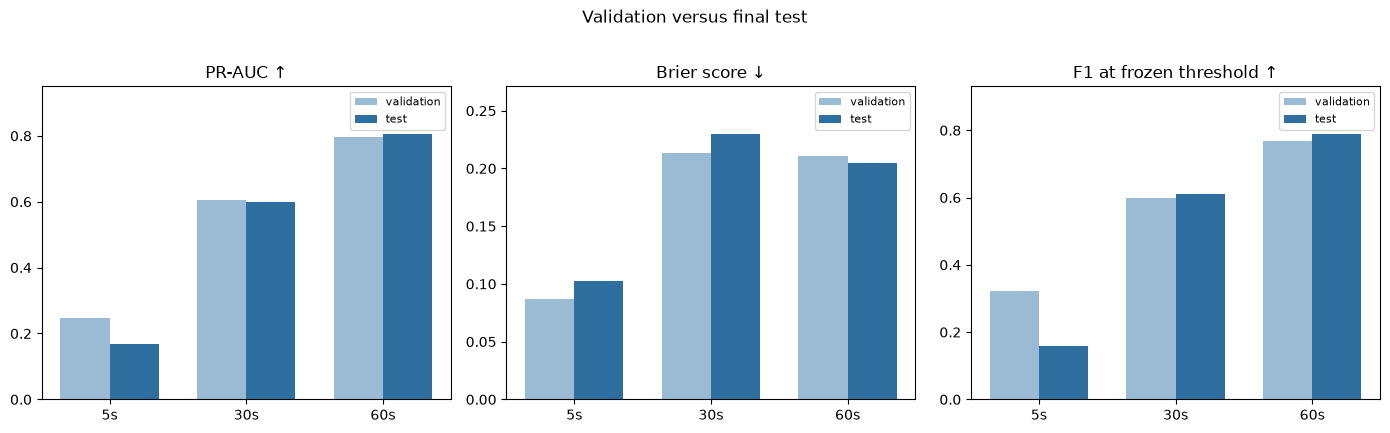

In [7]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, horizon in zip(axes, HORIZONS):
    horizon_predictions = test_predictions.loc[
        test_predictions["horizon_seconds"].eq(horizon)
    ]
    observed, predicted = calibration_curve(
        horizon_predictions["target_fill"],
        horizon_predictions["calibrated_probability"],
        n_bins=8,
        strategy="quantile",
    )
    ax.plot(predicted, observed, marker="o", color="#2f6f9f", label="frozen model")
    ax.plot([0, 1], [0, 1], linestyle="--", color="0.45", label="ideal")
    ax.set_title(f"{horizon}s")
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed fill rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)

fig.suptitle("Final test calibration", y=1.02)
fig.tight_layout()
calibration_figure_path = FIGURE_DIR / "final_test_calibration.png"
fig.savefig(calibration_figure_path, dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
metric_specs = [
    ("pr_auc", "PR-AUC", True),
    ("brier_score", "Brier score", False),
    ("f1", "F1 at frozen threshold", True),
]
for ax, (metric, label, higher_is_better) in zip(axes, metric_specs):
    x = np.arange(len(HORIZONS))
    validation_values = [
        policy["horizons"][str(h)]["validation_metrics"][metric] for h in HORIZONS
    ]
    test_values = [
        overall_metrics.set_index("horizon_seconds").loc[h, metric] for h in HORIZONS
    ]
    width = 0.36
    ax.bar(x - width / 2, validation_values, width, label="validation", color="#9bbbd4")
    ax.bar(x + width / 2, test_values, width, label="test", color="#2f6f9f")
    ax.set_xticks(x, [f"{h}s" for h in HORIZONS])
    ax.set_title(label + (" ↑" if higher_is_better else " ↓"))
    ax.set_ylim(0, max(validation_values + test_values) * 1.18)
    ax.legend(fontsize=8)

fig.suptitle("Validation versus final test", y=1.02)
fig.tight_layout()
comparison_figure_path = FIGURE_DIR / "final_test_validation_comparison.png"
fig.savefig(comparison_figure_path, dpi=180, bbox_inches="tight")
plt.show()


## Export the audit trail

The frozen validation policy remains unchanged. New artifacts are written separately and identify the exact policy hash and Git commit used for the final test evaluation.


In [8]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

metrics_path = RESULTS_DIR / "final_test_metrics.csv"
comparison_path = RESULTS_DIR / "validation_test_comparison.csv"
slice_path = RESULTS_DIR / "final_test_slice_metrics.csv"
predictions_path = RESULTS_DIR / "final_test_predictions.csv"
fold_audit_path = RESULTS_DIR / "final_test_fit_audit.csv"
summary_path = RESULTS_DIR / "final_test_summary.json"

overall_metrics.to_csv(metrics_path, index=False)
validation_test_comparison.to_csv(comparison_path, index=False)
slice_metrics.to_csv(slice_path, index=False)
test_predictions.to_csv(predictions_path, index=False)
fold_audit.to_csv(fold_audit_path, index=False)


def to_builtin(value):
    if isinstance(value, dict):
        return {str(key): to_builtin(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_builtin(item) for item in value]
    if isinstance(value, np.generic):
        return value.item()
    if pd.isna(value):
        return None
    return value


overall_summary = {}
for row in overall_metrics.to_dict("records"):
    horizon = str(int(row.pop("horizon_seconds")))
    overall_summary[horizon] = to_builtin(row)

summary = {
    "status": "final_test_evaluated",
    "source_commit": source_commit,
    "frozen_policy_sha256": policy_sha256,
    "policy_matches_source_commit": True,
    "worktree_clean_before_test_access": True,
    "random_seed": RANDOM_SEED,
    "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
    "test_rows": int(len(test_rows)),
    "fit_protocol": {
        "base_model_fit": "all eligible training rows only",
        "calibration_fit": "four expanding-window training OOF folds",
        "validation_use": "none after policy freeze",
        "test_use": "final evaluation only; identically rerun once after a display-only syntax error",
        "retuning_after_test": False,
    },
    "execution_note": (
        "The frozen workflow was rerun once after a display-only string syntax error "
        "halted the first attempt after scoring. No feature, model, calibration, "
        "threshold, or reported value was changed in response to test results."
    ),
    "overall_metrics": overall_summary,
    "artifacts": [
        metrics_path.name,
        comparison_path.name,
        slice_path.name,
        predictions_path.name,
        fold_audit_path.name,
        calibration_figure_path.name,
        comparison_figure_path.name,
    ],
}
summary_path.write_text(json.dumps(summary, indent=2, allow_nan=False) + "\n")

print("Saved final-test artifacts:")
for path in (
    metrics_path,
    comparison_path,
    slice_path,
    predictions_path,
    fold_audit_path,
    summary_path,
    calibration_figure_path,
    comparison_figure_path,
):
    print(" -", path)


Saved final-test artifacts:
 - /private/tmp/final_test_artifacts/final_test_metrics.csv
 - /private/tmp/final_test_artifacts/validation_test_comparison.csv
 - /private/tmp/final_test_artifacts/final_test_slice_metrics.csv
 - /private/tmp/final_test_artifacts/final_test_predictions.csv
 - /private/tmp/final_test_artifacts/final_test_fit_audit.csv
 - /private/tmp/final_test_artifacts/final_test_summary.json
 - /private/tmp/final_test_figures/final_test_calibration.png
 - /private/tmp/final_test_figures/final_test_validation_comparison.png


In [9]:
print("Final test evaluation complete — policy remains frozen.")
for row in overall_metrics.itertuples(index=False):
    pr_delta = validation_test_comparison.loc[
        validation_test_comparison["horizon_seconds"].eq(row.horizon_seconds),
        "delta_pr_auc",
    ].iloc[0]
    print(
        f"{row.horizon_seconds:>2}s | PR-AUC={row.pr_auc:.4f} "
        f"({row.pr_auc_ci_low:.4f}, {row.pr_auc_ci_high:.4f}) | "
        f"ROC-AUC={row.roc_auc:.4f} | Brier={row.brier_score:.4f} | "
        f"precision={row.precision:.3f} | recall={row.recall:.3f} | "
        f"F1={row.f1:.3f} | validation→test PR-AUC delta={pr_delta:+.4f}"
    )

high_positive = overall_metrics.loc[overall_metrics["predicted_fill_rate"].gt(0.90)]
if not high_positive.empty:
    horizons = ", ".join(f"{int(value)}s" for value in high_positive["horizon_seconds"])
    print(
        "Caution: the frozen F1 threshold predicts fills for more than 90% of eligible "
        f"orders at {horizons}; interpret this as a high-recall operating point."
    )


Final test evaluation complete — policy remains frozen.
 5s | PR-AUC=0.1696 (0.1369, 0.2185) | ROC-AUC=0.6163 | Brier=0.1023 | precision=0.223 | recall=0.122 | F1=0.158 | validation→test PR-AUC delta=-0.0771
30s | PR-AUC=0.5995 (0.5522, 0.6431) | ROC-AUC=0.6499 | Brier=0.2298 | precision=0.517 | recall=0.746 | F1=0.611 | validation→test PR-AUC delta=-0.0048
60s | PR-AUC=0.8052 (0.7764, 0.8332) | ROC-AUC=0.6896 | Brier=0.2051 | precision=0.658 | recall=0.985 | F1=0.789 | validation→test PR-AUC delta=+0.0077
Caution: the frozen F1 threshold predicts fills for more than 90% of eligible orders at 60s; interpret this as a high-recall operating point.


## Next research step

With the test set now closed, the next notebook should explain the frozen models without further optimization: global feature importance, directionality for the 5-second logistic model, permutation or SHAP-style explanations for the random forests, and a small set of order-level case studies. Survival analysis can then be treated as a distinct extension rather than mixed into the completed binary-classification track.
